# 使用miniPT开发自己的语言模型；

这个项目基于Andrej Karpathy的minGPT`https://github.com/karpathy/minGPT`。

旨在实现从头开始训练一个属于自己的字符级语言模型，了解构建数据处理、模型搭建、训练和测试的完整流程。

The MIT License (MIT) Copyright (c) 2020 Andrej Karpathy

Permission is hereby granted, free of charge, to any person obtaining a copy of this software and associated documentation files (the "Software"), to deal in the Software without restriction, including without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell copies of the Software, and to permit persons to whom the Software is furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.

## 一、依赖导入；

导入项目所需的所有Python库。⚠️这段代码很简单，不需要花太多的时间理解。

In [23]:
%%time

# 标准库导入。
import os;
import sys;
import json;
import time;
import math;
import random;
from ast import literal_eval;
from collections import defaultdict;
from dataclasses import dataclass;

# 科学计算和深度学习库。
import numpy as np;
import torch;
import torch.nn as nn;
from torch.nn import functional as F;
from torch.utils.data import Dataset;
from torch.utils.data.dataloader import DataLoader;

# 设置matplotlib中文字体支持。
import matplotlib.pyplot as plt;
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans'];
plt.rcParams['axes.unicode_minus'] = False;

CPU times: user 120 µs, sys: 10 µs, total: 130 µs
Wall time: 135 µs


## 二、常量定义；

定义项目中使用的各种配置参数和工具类。

In [24]:
%%time

# 设置随机种子，确保实验结果可复现。
def set_seed(seed):
    random.seed(seed);
    np.random.seed(seed);
    torch.manual_seed(seed);
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed);
set_seed(1298);

@dataclass # 默认模型配置。
class Config:
    batch_size: int = 64;
    block_size: int = 128;
    n_embd: int = 512;
    vocab_size: int = None;
    n_layer: int = 2;
    n_head: int = 2;
    dropout: float = 0.1;
    bias: bool = True;
    grad_norm_clip: float = 1.0; # 梯度裁剪阈值。
config = Config();


train_data = "/kaggle/input/datasets/ailananjuxi/xiyouji/xyj.txt"; # 要训练的文本数据集。

IS_PRINT_TRAIN_PROCESS = 0; # 是否打印训练具体过程。

WORK_DIR = './out/my_lm'; # 工作目录，用于保存模型、日志等。

LEARNING_RATE = 15e-4; # 学习率。
MAX_ITERS = 1000;       # 训练次数。
EVAL_INTERVAL = 5;    # 评估间隔，每训练50次迭代评估一次模型性能。

device = 'cuda' if torch.cuda.is_available() else 'cpu';
print(f"使用设备: {device} !");

使用设备: cuda !
CPU times: user 2.88 ms, sys: 1.91 ms, total: 4.79 ms
Wall time: 4.5 ms


## 三、数据处理；

创建数据集类，将文本数据转换为模型可以处理的数字序列。

In [25]:
class CharDataset(Dataset):# 字符级数据集类。
    def __init__(self, data, block_size=128):
        self.block_size = block_size;

        # 获取所有唯一字符并排序。
        chars = sorted(list(set(data)));
        data_size, vocab_size = len(data), len(chars);

        print(f"数据集统计:");
        print(f"    总字符数: {data_size} ！");
        print(f"    唯一字符数: {vocab_size} ！");

        # 创建字符到索引、索引到字符的映射。
        self.stoi = {ch: i for i, ch in enumerate(chars)};
        self.itos = {i: ch for i, ch in enumerate(chars)};
        self.vocab_size = vocab_size;
        self.data = data;

    def get_vocab_size(self):
        return self.vocab_size;

    def get_block_size(self):
        return self.block_size;

    def __len__(self):
        return len(self.data) - self.block_size;

    def __getitem__(self, idx):
        # 截取(block_size + 1)长度的字符块。
        chunk = self.data[idx:idx + self.block_size + 1];
        # 将字符转换为索引。
        dix = [self.stoi[s] for s in chunk];
        # x是输入序列，y是目标序列（x向右偏移一位）。
        x = torch.tensor(dix[:-1], dtype=torch.long);
        y = torch.tensor(dix[1:], dtype=torch.long);
        return x, y;

### 加载训练数据：

In [26]:
# 如果存在外部数据文件，优先使用。
if os.path.exists(train_data):
    with open(train_data, 'r', encoding='utf-8') as f:
        text = f.read();
    print(f"✅已经从文件 {train_data} 加载数据 !");

✅已经从文件 /kaggle/input/datasets/ailananjuxi/xiyouji/xyj.txt 加载数据 !


### 建立字典、建立编码器解码器等：

In [27]:
# 创建数据集实例。
train_dataset = CharDataset(text, block_size=config.block_size);
config.vocab_size = train_dataset.get_vocab_size();
print(f"词汇表大小: {config.vocab_size} !");
print(f"序列长度: {train_dataset.get_block_size()} !");

数据集统计:
    总字符数: 741374 ！
    唯一字符数: 4200 ！
词汇表大小: 4200 !
序列长度: 128 !


### 看数据：

In [28]:
# # 显示词汇表。
# print("词汇表中的字符:");
# vocab_chars = [train_dataset.itos[i] for i in range(train_dataset.vocab_size)];
# for i, ch in enumerate(vocab_chars):
#     display_ch = ch if ch != '\\n' else '\\n';
#     display_ch = display_ch if display_ch != ' ' else '[空格]';
#     print(f"  {i}: '{display_ch}'", end="");
#     if (i + 1) % 8 == 0:
#         print();
# print("\\n");

# # 查看一个样本。
# sample_idx = 0;
# x, y = train_dataset[sample_idx];
# print(f"\n样本 {sample_idx}:");
# input_str = ''.join([train_dataset.itos[int(i)] for i in x]);
# target_str = ''.join([train_dataset.itos[int(i)] for i in y]);
# print(f"输入 (x): {repr(input_str[:50])} ！");
# print(f"目标 (y): {repr(target_str[:50])} ！");

# # 可视化字符频率。
# from collections import Counter;
# char_counts = Counter(text);
# most_common = char_counts.most_common(train_dataset.get_vocab_size());
# chars = [ch if ch != '\\n' else '\\n' for ch, _ in most_common];
# counts = [count for _, count in most_common];

# plt.figure(figsize=(12, 5));
# plt.bar(chars, counts);
# plt.xlabel('字符:');
# plt.ylabel('出现次数:');
# plt.title(f'文本中的字符频率!');
# plt.xticks(rotation=45);
# plt.tight_layout();
# plt.show();

## 四、模型；

实现GPT模型的各个组件，包括注意力机制、Transformer块和完整的GPT模型。

### GELU激活函数实现：

In [29]:
class NewGELU(nn.Module):
    """
    GELU激活函数的实现，用于Transformer中的前馈网络。
    相比ReLU，GELU在负数区域有更平滑的梯度。
    """
    def forward(self, x):
        
        temp = 0.5 * x * (1.0 + torch.tanh(math.sqrt(2.0 / math.pi) * (x + 0.044715 * torch.pow(x, 3.0))));
        
        return temp;

### 多头因果自注意力层：

In [30]:
from ast import Is


class CausalSelfAttention(nn.Module):
    """
    多头因果自注意力层，是Transformer的核心组件。
    "因果"意味着每个位置只能关注到它之前的位置，确保自回归生成。
    """
    def __init__(self, config):
        super().__init__();
        assert config.n_embd % config.n_head == 0;

        # 线性投影，同时生成Q、K、V。
        self.c_attn = nn.Linear(config.n_embd, 3*config.n_embd);
        # 输出投影。
        self.c_proj = nn.Linear(config.n_embd, config.n_embd);
        # Dropout正则化。
        self.attn_dropout = nn.Dropout(config.dropout);
        self.resid_dropout = nn.Dropout(config.dropout);

        # 注册因果掩码，防止关注到未来的token。
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size));
        self.n_head = config.n_head;
        self.n_embd = config.n_embd;

    def forward(self, x):

        B, T, C = x.size(); # B句子数量、T句子长度、C句子特征维度。
    
        # 计算Q、K、V。
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2);

        # 调整维度为多头形式。
        k = k.view(B, T, self.n_head, C//self.n_head).transpose(1, 2);
        q = q.view(B, T, self.n_head, C//self.n_head).transpose(1, 2);
        v = v.view(B, T, self.n_head, C//self.n_head).transpose(1, 2);

        # 计算注意力分数。
        # k转置：
        kt = k.transpose(-2, -1);

        # Q*K^T：
        att = q@kt;

        # 缩放：
        att = att*(1.0/math.sqrt(k.size(-1)));

        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'));

        att = F.softmax(att, dim=-1);

        att = self.attn_dropout(att);

        # 加权求和并重组。
        y = att @ v;

        y = y.transpose(1, 2).contiguous().view(B, T, C);
        
        y = self.resid_dropout(self.c_proj(y));
        
        return y;


### Transformer块：

In [31]:
class Block(nn.Module):
    """
    标准的Transformer块，包含注意力层和前馈网络。
    使用预归一化（Pre-LN）架构。
    """
    def __init__(self, config):
        super().__init__();
        self.ln_1 = nn.LayerNorm(config.n_embd);
        self.attn = CausalSelfAttention(config);
        self.ln_2 = nn.LayerNorm(config.n_embd);
        self.mlp = nn.ModuleDict(dict(
            c_fc=nn.Linear(config.n_embd, 4*config.n_embd),
            act=NewGELU(),
            c_proj=nn.Linear(4*config.n_embd, config.n_embd),
            dropout=nn.Dropout(config.dropout),
        ));
        m = self.mlp;
        self.mlpf = lambda x: m.dropout(m.c_proj(m.act(m.c_fc(x))));

    def forward(self, x):
        temp_1 = x;

        x = self.ln_1(x);
        
        x = self.attn(x);
        
        x = temp_1 + x;# 残差连接。temp_1是原来的x。
        # 第二个子层：
        temp_2 = x;
        
        x = self.ln_2(x);
        
        x = self.mlpf(x);
        
        x = temp_2 + x;
        
        return x;

### GPT语言模型：

In [32]:
class GPT(nn.Module):
    """
    GPT语言模型的完整实现。
    包含词嵌入、位置嵌入、Transformer块堆叠和语言模型头。
    """

    def __init__(self, config):
        super().__init__();
        assert config.vocab_size is not None;
        assert config.block_size is not None;
        self.block_size = config.block_size;

        # Transformer主体。
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ));
        # 语言模型头，将隐藏状态映射到词汇表。
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False);

        # 初始化权重。
        self.apply(self._init_weights);
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                torch.nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer));

        # 报告参数数量。
        n_params = sum(p.numel() for p in self.transformer.parameters());
        print(f"模型参数数量: {n_params / 1e6:.2f}M");

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02);
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias);
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02);
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.zeros_(module.bias);
            torch.nn.init.ones_(module.weight);

    def configure_optimizers(self):
        """
        配置优化器，对偏置和归一化参数进行特殊处理。
        """
        decay = set();
        no_decay = set();
        whitelist_weight_modules = (torch.nn.Linear,);
        blacklist_weight_modules = (torch.nn.LayerNorm, torch.nn.Embedding);

        for mn, m in self.named_modules():
            for pn, p in m.named_parameters():
                fpn = f"{mn}.{pn}" if mn else pn;

                if pn.endswith('bias'):
                    no_decay.add(fpn);
                elif pn.endswith('weight') and isinstance(m, whitelist_weight_modules):
                    decay.add(fpn);
                elif pn.endswith('weight') and isinstance(m, blacklist_weight_modules):
                    no_decay.add(fpn);

        decay.remove('lm_head.weight');

        param_dict = {pn: p for pn, p in self.named_parameters()};
        inter_params = decay & no_decay;
        union_params = decay | no_decay;

        optim_groups = [
            {"params": [param_dict[pn] for pn in sorted(list(decay))], "weight_decay": 0.1},
            {"params": [param_dict[pn] for pn in sorted(list(no_decay))], "weight_decay": 0.0},
        ];

        optimizer = torch.optim.AdamW(optim_groups, lr=LEARNING_RATE, betas=(0.9, 0.95));
        return optimizer;

    def generate(self, idx, max_new_tokens, temperature=1.0, do_sample=False, top_k=None):
        """
        自回归生成文本。
        idx: 初始上下文，形状为(B, T)。
        max_new_tokens: 要生成的新token数量。
        temperature: 控制采样的随机性。
        do_sample: 是否采样，False则使用贪婪解码。
        top_k: 只从概率最高的k个token中采样。
        """
        for _ in range(max_new_tokens):
            # 截取到block_size。
            idx_cond = idx if idx.size(1) <= self.block_size else idx[:, -self.block_size:];
            logits, _ = self(idx_cond);
            logits = logits[:, -1, :] / temperature;

            # Top-k过滤。
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)));
                logits[logits < v[:, [-1]]] = -float('Inf');

            # 计算概率。
            probs = F.softmax(logits, dim=-1);

            # 采样或贪婪选择。
            if do_sample:
                idx_next = torch.multinomial(probs, num_samples=1);
            else:
                _, idx_next = torch.topk(probs, k=1, dim=-1);

            idx = torch.cat((idx, idx_next), dim=1);

        return idx;
        
    def forward(self, idx, targets=None):
        torch.set_printoptions(sci_mode=False);

        device = idx.device;
        b, t = idx.size();
        assert t <= self.block_size, f"序列长度{t}超过最大长度{self.block_size}";

        # 词嵌入 + 位置嵌入。
        pos = torch.arange(0, t, dtype=torch.long, device=device).unsqueeze(0);

        tok_emb = self.transformer.wte(idx);
        tok_emb = self.transformer.wte(idx);
        
        pos_emb = self.transformer.wpe(pos);

        x = tok_emb + pos_emb;
        
        x = self.transformer.drop(x);

        # 通过Transformer块。
        for block in self.transformer.h:
            x = block(x);
        x = self.transformer.ln_f(x);

        # 计算语言模型损失。
        logits = self.lm_head(x);
        loss = None;
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1);

        return logits, loss;

### 实例化模型：

In [33]:
model = GPT(config);
model = model.to(device);
print(model);

模型参数数量: 8.52M
GPT(
  (transformer): ModuleDict(
    (wte): Embedding(4200, 512)
    (wpe): Embedding(128, 512)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-1): 2 x Block(
        (ln_1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=512, out_features=1536, bias=True)
          (c_proj): Linear(in_features=512, out_features=512, bias=True)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (mlp): ModuleDict(
          (c_fc): Linear(in_features=512, out_features=2048, bias=True)
          (act): NewGELU()
          (c_proj): Linear(in_features=2048, out_features=512, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head

## 五、训练；

实现训练循环，包括前向传播、反向传播和参数更新。

In [34]:
class Trainer:
    def __init__(self, config, model, train_dataset):
        self.config = config;
        self.model = model;
        self.train_dataset = train_dataset;
        self.callbacks = defaultdict(list);
        self.device = device;

        self.iter_num = 0;
        self.iter_time = 0.0;
        self.iter_dt = 0.0;

    def add_callback(self, onevent, callback):
        self.callbacks[onevent].append(callback);

    def set_callback(self, onevent, callback):
        self.callbacks[onevent] = [callback];

    def trigger_callbacks(self, onevent):
        for callback in self.callbacks.get(onevent, []):
            callback(self);
    def run(self):
        model, config = self.model, self.config;

        # 设置优化器。
        optimizer = model.configure_optimizers();

        # 设置数据加载器。
        train_loader = DataLoader(
            self.train_dataset,
            sampler=torch.utils.data.RandomSampler(
                self.train_dataset, replacement=True, num_samples=int(1e10)
            ),
            shuffle=False,
            pin_memory=True,
            batch_size=config.batch_size,
            num_workers=0,
        );

        model.train();
        self.iter_num = 0;
        self.iter_time = time.time();
        data_iter = iter(train_loader);

        # 记录损失历史。
        self.loss_history = [];

        while True:
            try:
                batch = next(data_iter);
            except StopIteration:
                data_iter = iter(train_loader);
                batch = next(data_iter);

            batch = [t.to(self.device) for t in batch];
            x, y = batch;

            # 前向传播。
            logits, loss = model(x, y);

            # 反向传播和优化。
            model.zero_grad(set_to_none=True);
            loss.backward();
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.grad_norm_clip);
            optimizer.step();

            self.loss = loss;
            self.trigger_callbacks('on_batch_end');
            self.iter_num += 1;

            tnow = time.time();
            self.iter_dt = tnow - self.iter_time;
            self.iter_time = tnow;

            if self.iter_num % EVAL_INTERVAL == 0:
                print(f"step {self.iter_num}: loss = {loss.item():.6f}, time = {self.iter_dt:.3f}s")


            # 记录损失。
            self.loss_history.append(loss.item());

            # 终止条件。
            if MAX_ITERS is not None and self.iter_num >= MAX_ITERS:
                break;

        return self.loss_history;

In [35]:
# 执行训练。
trainer = Trainer(config, model, train_dataset);
loss_history = trainer.run();
print("✅训练完成！");

step 5: loss = 7.528857, time = 0.151s
step 10: loss = 7.485179, time = 0.150s
step 15: loss = 7.366072, time = 0.153s
step 20: loss = 7.342485, time = 0.153s
step 25: loss = 7.289547, time = 0.157s
step 30: loss = 7.141448, time = 0.159s
step 35: loss = 7.199205, time = 0.158s
step 40: loss = 6.984007, time = 0.157s
step 45: loss = 7.072401, time = 0.156s
step 50: loss = 6.976205, time = 0.161s
step 55: loss = 6.984648, time = 0.162s
step 60: loss = 6.951346, time = 0.163s
step 65: loss = 6.988867, time = 0.162s
step 70: loss = 6.968500, time = 0.162s
step 75: loss = 6.856338, time = 0.161s
step 80: loss = 6.809608, time = 0.161s
step 85: loss = 6.700806, time = 0.164s
step 90: loss = 6.768518, time = 0.168s
step 95: loss = 6.724249, time = 0.163s
step 100: loss = 6.683008, time = 0.163s
step 105: loss = 6.698416, time = 0.165s
step 110: loss = 6.609140, time = 0.164s
step 115: loss = 6.630637, time = 0.164s
step 120: loss = 6.589842, time = 0.166s
step 125: loss = 6.514044, time = 0.

/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 36845 (\N{CJK UNIFIED IDEOGRAPH-8FED}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 20195 (\N{CJK UNIFIED IDEOGRAPH-4EE3}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout();
/tmp/ipykernel_57/1829084220.py:22: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missin

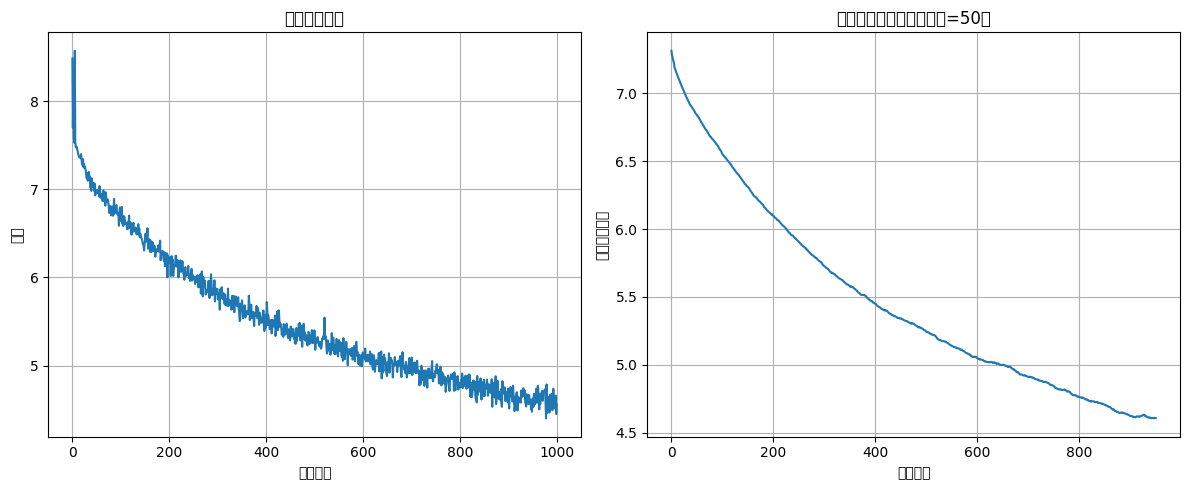

最终损失: 4.5598
平均损失（最后100次）: 4.6164


In [36]:
# 绘制训练损失曲线。
plt.figure(figsize=(12, 5));

# 原始损失。
plt.subplot(1, 2, 1);
plt.plot(loss_history);
plt.xlabel('迭代次数');
plt.ylabel('损失');
plt.title('训练损失曲线');
plt.grid(True);

# 平滑后的损失。
plt.subplot(1, 2, 2);
window_size = 50;
smoothed = np.convolve(loss_history, np.ones(window_size)/window_size, mode='valid');
plt.plot(smoothed);
plt.xlabel('迭代次数');
plt.ylabel('损失（平滑）');
plt.title(f'训练损失曲线（窗口大小={window_size}）');
plt.grid(True);

plt.tight_layout();
plt.show();

print(f"最终损失: {loss_history[-1]:.4f}");
print(f"平均损失（最后100次）: {np.mean(loss_history[-100:]):.4f}");

## 六、效果测试；

使用训练好的模型生成文本，评估模型效果。

In [39]:
# 加载保存的模型（如果需要）。
# model.load_state_dict(torch.load(os.path.join(WORK_DIR, "model.pt")));
model.eval();

def generate_text(prompt, max_tokens=5, temperature=0.8, top_k=10):
    context = torch.tensor(
        [train_dataset.stoi.get(s, 0) for s in prompt],
        dtype=torch.long
    )[None, ...].to(device);

    with torch.no_grad():
        y = model.generate(context, max_tokens, temperature=temperature, do_sample=True, top_k=top_k)[0];

    completion = ''.join([train_dataset.itos[int(i)] for i in y]);
    return completion;


prompt = "孙";

generated = generate_text(prompt, max_tokens=100, temperature=0.8);
print(f"生成结果: {generated}");

生成结果: 孙行者道：“你是个‘金箍儿’？”
　　　那呆子听得说，即忙纵筋斗云，直至殿上，把三藏与八戒、沙僧，径至前，
只见那门里走出一个大小妖，一齐下，就是一个大小妖，把那些妖精，一个个
个个个
喧哗，一齐上前，


In [38]:
# 保存模型配置和词汇表映射。
import pickle;

model_info = {
    'vocab_size': train_dataset.vocab_size,
    'block_size': train_dataset.block_size,
    'stoi': train_dataset.stoi,
    'itos': train_dataset.itos,
    'n_layer': config.n_layer,
    'n_head': config.n_head,
    'n_embd': config.n_embd,
};

os.makedirs(WORK_DIR, exist_ok=True);

with open(os.path.join(WORK_DIR, 'model_info.pkl'), 'wb') as f:
    pickle.dump(model_info, f);

with open(os.path.join(WORK_DIR, 'model_info.json'), 'w', encoding='utf-8') as f:
    json.dump({k: v for k, v in model_info.items() if k not in ['stoi', 'itos']}, f, ensure_ascii=False, indent=2);

print(f"模型信息已保存到 {WORK_DIR}");
print("\\n项目文件结构:");
for root, dirs, files in os.walk(WORK_DIR):
    level = root.replace(WORK_DIR, '').count(os.sep);
    indent = ' ' * 2 * level;
    print(f"{indent}{os.path.basename(root)}/");
    subindent = ' ' * 2 * (level + 1);
    for file in files:
        filepath = os.path.join(root, file);
        size = os.path.getsize(filepath);
        print(f"{subindent}{file} ({size / 1024:.1f} KB)");

模型信息已保存到 ./out/my_lm
\n项目文件结构:
my_lm/
  model_info.pkl (68.6 KB)
  model_info.json (0.1 KB)
